# Unequal Housing Conditions: EDA for Proactive Datasets

## Summary

In April 2022, Health Affairs journal [published research](https://drive.google.com/file/d/1UNsZFoiROnXif1XU6L2_kiELQ-xJmMia/view?usp=share_link) correlating racial makeup of neighborhoods to unequal housing conditions and code enforcement related to asthma triggers. The researchers found that, when analyzing publicly-available 311 data between 2011 and 2021, predominantly white neighborhoods report fewer conditions known to cause or exacerbate asthma, and when they do, they experience faster case closure rates, fewer overdue requests, and higher chances of the request resulting in a repair. 

While the above study was predicated on the publicly-available 311 data where renters call to put in their complaints before the City react (we term this data as reactive dataset), there has been a policy which allows the [City to randomly inspect housing](https://www.boston.gov/departments/inspectional-services/inspecting-housing-boston) to ensure safety and protect the health of the public.

Thus, the inspectional service department developed [an algorithm](https://drive.google.com/file/d/1Cn444cCKTDTU2sqXXCiqzDLha3wGvczA/view?usp=drive_link) to randomly assign houses for inspection. This proactive approach would be analyze to explore and determine the efficacy of the policy as it pertains to ensuring equitable distribution of the City's housing safety protocols. 


## EDA Problem Statement

Datasets: 
* 311 Requests, 2020 - Present
* Proactive Inspections Data, 2020 - Present

Explore the different features in the dataset to see if it will good for feature selection and determining feature importance.
* If possible, a predictive model could be developed to using property features, location & other factors as IVs.
* Graph Analysis; to connect different locations using various nodes and edges to gain insights into likely violators.
* Similarity Analysis/CLustering based on different features.



In [1]:
#####  Import libraries for Boston City DoIT Analytics database..
import os 
import civis

# import libraries for data pre-processing
import pandas as pd
import numpy as np
from datetime import datetime
import datetime as datetime

# import libraries for visualization
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
from chart_studio import plotly
import plotly.offline as pyoff
import plotly.graph_objs as go
import plotly.express as px


from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
init_notebook_mode(connected=True)        # Display plot on notebook while the kernel is running


# utils
import warnings 
warnings.filterwarnings('ignore')


In [2]:
### import os
#import civis
#import pandas as pd

os.environ['PYTHONPATH']='.'
os.environ['CIVIS_API_KEY']='iNtRtV8mWJYVuDKqr9XULieOXud8XndxiyWpFnSPUxs'

# Define the SQL query for proactive inspections from 2020 - present 
sql_proactive_inspections = """
SELECT * FROM isd_internal_data.proactive_inspections 
WHERE scheddttm >= '2020-01-01 00:00:00+00'
"""
# Define the SQL query for proactive violations from 2020 - present 
sql_proactive_violations = """
SELECT * FROM isd_internal_data.proactive_violations
WHERE scheddttm >= '2020-01-01 00:00:00+00'
"""

df_proactive_inspections = civis.io.read_civis_sql(sql_proactive_inspections,
                                            database='Boston',
                                            use_pandas=True)
df_proactive_violations = civis.io.read_civis_sql(sql_proactive_violations,
                                            database='Boston',
                                            use_pandas=True)


In [3]:
df_proactive_inspections.head()


,licensecat,licenseno,comments_licappl,expdttm,issby,issdttm,modby_licappl,moddttm_licappl,licenseby,addby_licappl,...,gpsx,gpsy,gpsz,postdir,state,stname,stno,suffix,zip,gps_geom_2249
0,Condo,RINS-513784,"32 Sidlaw Road, Unit 11",2027-08-19 04:00:00+00,,NaN,HSNINTFC,2022-11-16 12:42:37.23+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
1,MultiFam,RINS-479165,NaN,2027-02-14 05:00:00+00,,NaN,HSNINTFC,2022-05-02 11:51:02.667+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
2,MultiFam,RINS-494743,NaN,2027-10-07 04:00:00+00,,NaN,HSNINTFC,2022-10-14 15:23:40.493+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
3,Condo,RINS-512542,NaN,2027-09-13 04:00:00+00,,NaN,HSNINTFC,2022-11-10 15:44:30.85+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
4,MultiFam,RINS-494739,NaN,2027-10-07 04:00:00+00,,NaN,HSNINTFC,2022-10-14 15:23:37.48+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN


In [4]:
sub = df_proactive_inspections[['apkey','licensecat','licenseno','addrkey','result','adddttm','scheddttm','compdttm','resultdttm','resultby','comments','gpsx','gpsy','gps_geom_2249']]


In [ ]:
# Create a geometry column using 'gpsx' and 'gpsy', we could have used longitude and lat respectively if we had those instead.
# df_proactive_inspections['geometry'] = gpd.points_from_xy(df_proactive_inspections.gpsx, df_proactive_inspections.gpsy, crs=4326)

# Convert the pandas DataFrame to a geopandas GeoDataFrame
#gdf = gpd.GeoDataFrame(df_proactive_inspections, geometry='geometry', crs='EPSG:4326')
#gdf.head()

In [ ]:
# Convert the pandas DataFrame to a geopandas GeoDataFrame
# gdf = gpd.GeoDataFrame(sub, geometry=gpd.points_from_xy(sub.gpsx,sub.gpsy, crs=4326))

# gdf.head()


In [5]:
sub.head()


,apkey,licensecat,licenseno,addrkey,result,adddttm,scheddttm,compdttm,resultdttm,resultby,comments,gpsx,gpsy,gps_geom_2249
0,2634600,Condo,RINS-513784,1,Pass,2022-11-15 14:49:33.363+00,2022-08-19 04:00:00+00,NaN,2022-08-19 04:00:00+00,110163,NaN,NaN,NaN,NaN
1,2485376,MultiFam,RINS-479165,1,Pass,2022-04-29 16:58:20.977+00,2022-02-14 05:00:00+00,NaN,2022-02-14 05:00:00+00,110163,NaN,NaN,NaN,NaN
2,2599783,MultiFam,RINS-494743,1,Pass,2022-10-14 13:36:17.26+00,2022-10-07 04:00:00+00,NaN,2022-10-07 04:00:00+00,110163,NaN,NaN,NaN,NaN
3,2631828,Condo,RINS-512542,1,Pass,2022-11-10 15:28:47.35+00,2022-09-13 04:00:00+00,NaN,2022-09-13 04:00:00+00,110163,NaN,NaN,NaN,NaN
4,2599779,MultiFam,RINS-494739,1,Pass,2022-10-14 13:36:15.477+00,2022-10-07 04:00:00+00,NaN,2022-10-07 04:00:00+00,110163,NaN,NaN,NaN,NaN


In [6]:
sub.tail()


,apkey,licensecat,licenseno,addrkey,result,adddttm,scheddttm,compdttm,resultdttm,resultby,comments,gpsx,gpsy,gps_geom_2249
189032,2671814,MultiFam,RINS-520193,697480,,2023-06-06 19:25:26.88+00,2023-08-24 19:16:00+00,NaN,NaN,,NaN,770981.906785,2.951567e+06,0101000020C9080000411546D04B87274180790E5FC784...
189033,2671814,MultiFam,RINS-520193,697480,Fail,2023-01-30 15:50:54.81+00,2023-04-03 19:09:00+00,2023-04-03 15:44:00+00,2023-04-03 15:44:00+00,110900,Zoe Agorianitis 617-536-6466<div>Natty please ...,770981.906785,2.951567e+06,0101000020C9080000411546D04B87274180790E5FC784...
189034,2656485,MultiFam,RINS-518089,697548,Pass,2022-12-27 14:34:33.113+00,2023-03-27 17:22:00+00,2023-03-27 14:10:00+00,2023-03-27 14:10:00+00,149875,Greg Coleman 617-990-4384&nbsp; COF paid &amp;...,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...
189035,2656483,MultiFam,RINS-518087,697548,Pass,2022-12-27 14:34:29.01+00,2023-03-17 19:40:00+00,2023-03-17 14:23:00+00,2023-03-17 14:23:00+00,110900,Greg Coleman 617-990-4384 COF paid &amp; vacant,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...
189036,2656482,MultiFam,RINS-518086,697548,Pass,2022-12-27 14:34:27.053+00,2023-03-02 15:06:00+00,2023-03-02 14:35:00+00,2023-03-02 14:35:00+00,149875,Greg Coleman 617-990-4384 COF vacant paid,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...


### Conducting EDA

Exploratory data analysis to dig deep in order to better understand basic information such as record counts, data types, and missingness etc. 


In [7]:
sub.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189037 entries, 0 to 189036
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   apkey          189037 non-null  int64  
 1   licensecat     189037 non-null  object 
 2   licenseno      189037 non-null  object 
 3   addrkey        189037 non-null  int64  
 4   result         189037 non-null  object 
 5   adddttm        189037 non-null  object 
 6   scheddttm      189037 non-null  object 
 7   compdttm       142603 non-null  object 
 8   resultdttm     147515 non-null  object 
 9   resultby       189037 non-null  object 
 10  comments       140134 non-null  object 
 11  gpsx           188667 non-null  float64
 12  gpsy           188667 non-null  float64
 13  gps_geom_2249  188667 non-null  object 
dtypes: float64(2), int64(2), object(10)
memory usage: 20.2+ MB


There are 189037 records in the dataset with some columns having missing records.
* The missing records in the **'compdttm'** means an inspection has not been completed in those units, we shall look into that in details..


In [8]:
# Count the number of empty rows in the 'compdttm' column.
empty_rows = sub['compdttm'].isnull().sum()

# Count the number of rows with empty strings in the 'compdttm' column.
empty_strings = (sub['compdttm'] == '').sum()

# Calculate the total number of empty rows or strings in the 'compdttm' column.
total_empty = empty_rows + empty_strings
total_empty


46434

### Uninspected Units
**46,434** units were not inspected


In [9]:
# Drop rows where 'compdttm' column is either empty or contains an empty string.
sub.dropna(subset=['compdttm'], inplace=True)


In [10]:
# Check the todal number of observations again looking at the tail of the dataset
sub.tail()


,apkey,licensecat,licenseno,addrkey,result,adddttm,scheddttm,compdttm,resultdttm,resultby,comments,gpsx,gpsy,gps_geom_2249
189031,2671814,MultiFam,RINS-520193,697480,Fail,2023-04-03 15:50:53.47+00,2023-06-06 16:52:00+00,2023-06-06 19:23:00+00,2023-06-06 19:23:00+00,149875,Zoe Agorianitis 617-536-6466-Arrival 10:00-Lef...,770981.906785,2.951567e+06,0101000020C9080000411546D04B87274180790E5FC784...
189033,2671814,MultiFam,RINS-520193,697480,Fail,2023-01-30 15:50:54.81+00,2023-04-03 19:09:00+00,2023-04-03 15:44:00+00,2023-04-03 15:44:00+00,110900,Zoe Agorianitis 617-536-6466<div>Natty please ...,770981.906785,2.951567e+06,0101000020C9080000411546D04B87274180790E5FC784...
189034,2656485,MultiFam,RINS-518089,697548,Pass,2022-12-27 14:34:33.113+00,2023-03-27 17:22:00+00,2023-03-27 14:10:00+00,2023-03-27 14:10:00+00,149875,Greg Coleman 617-990-4384&nbsp; COF paid &amp;...,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...
189035,2656483,MultiFam,RINS-518087,697548,Pass,2022-12-27 14:34:29.01+00,2023-03-17 19:40:00+00,2023-03-17 14:23:00+00,2023-03-17 14:23:00+00,110900,Greg Coleman 617-990-4384 COF paid &amp; vacant,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...
189036,2656482,MultiFam,RINS-518086,697548,Pass,2022-12-27 14:34:27.053+00,2023-03-02 15:06:00+00,2023-03-02 14:35:00+00,2023-03-02 14:35:00+00,149875,Greg Coleman 617-990-4384 COF vacant paid,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...


In [11]:
# Get the unique values from the 'result' column
unique_results = sub['result'].unique()
unique_results


array(['Fail', 'Pass', 'Hold', ' '], dtype=object)

Does **'Hold' and the empty strings** for results imply the inspection is yet to be completed? 
Maybe we combined both as incomplete IC and keep it in the analysis instead of the convenience of dropping both.

* An empty string should not have a completion date, since it hasnt been inspected.


In [12]:
# Combine 'Hold' and ' ' categories and rename to 'IC', thus incomplete
sub['result'] = sub['result'].replace({'Hold': 'IC', ' ': 'IC'})
unique_results = sub['result'].unique()
unique_results


array(['Fail', 'Pass', 'IC'], dtype=object)

In [13]:
# Convert 'Fail' to 0 and 'Pass' to 1 and 'IC' to 2
sub['result'] = sub['result'].map({'Fail': 0, 'Pass': 1, 'IC': 2})

#Print the unique values in the 'result' column to verify the changes
unique_results = sub['result'].unique()
unique_results


array([0, 1, 2], dtype=int64)

In [14]:
# Calculate the count and percentage of the results

result_counts = sub['result'].value_counts()
result_percentages = sub['result'].value_counts(normalize=True) * 100

# Create a DataFrame to display the result
result_table = pd.DataFrame({'Count': result_counts, 'Percentage': result_percentages})

# Format the percentage column to display with two decimal places
result_table['Percentage'] = result_table['Percentage'].map('{:.2f}%'.format)

# Display the result table
print(result_table)


        Count Percentage
result                  
0       75310     52.81%
1       67251     47.16%
2          42      0.03%


#### Result Details
* Zero represents failed inspections, whereas One represent passed inspections
* There 52.8% failed inspections and approximately 47.17% passed inspections
* The 0.03% is Incomplete, we will ignore the ICs for ease of analysis

#### Owner License Analysis

In [15]:
unique_license_category = sub['licensecat'].unique()
df_unique_license_category = pd.DataFrame({'Unique License Category': unique_license_category})

# Display the DataFrame
print(df_unique_license_category)


  Unique License Category
0                MultiFam
1                  1-3FAM
2                  4-6FAM
3                      SF
4                   Condo
5                        


In [16]:
# Calculate the count and percentage of the owner's license category

license_category_counts = sub['licensecat'].value_counts()
license_category_percentages = sub['licensecat'].value_counts(normalize=True) * 100

# Create a DataFrame to display the license category
license_category_table = pd.DataFrame({'Count': license_category_counts, 'Percentage': license_category_percentages})

# Format the percentage column to display with two decimal places
license_category_table['Percentage'] = license_category_table['Percentage'].map('{:.2f}%'.format)

# Display the license category table
print(license_category_table)


             Count Percentage
licensecat                   
MultiFam    107600     75.45%
1-3FAM       14438     10.12%
4-6FAM       11390      7.99%
              6158      4.32%
Condo         2841      1.99%
SF             176      0.12%


We have more Multi family houses (75%) but 6186 (4.23%) of the units were not categorized
* Is the default a MultiFamily house or we'd be better off dropping this records?
* I will drop it for now.


In [17]:
# List of names to keep in the 'licensecat' column.
names_to_keep = ['Condo', 'MultiFam', '1-3FAM', '4-6FAM', 'SF']

# Keep only the rows with names from the 'names_to_keep' list in the 'licensecat' column.
sub = sub[sub['licensecat'].isin(names_to_keep)].copy()

# If you want to reset the index after keeping the rows:
sub.reset_index(drop=True, inplace=True)


In [18]:
# Calculate the count and percentage of the owner's license category

license_category_counts = sub['licensecat'].value_counts()
license_category_percentages = sub['licensecat'].value_counts(normalize=True) * 100

# Create a DataFrame to display the license category
license_category_table = pd.DataFrame({'Count': license_category_counts, 'Percentage': license_category_percentages})

# Format the percentage column to display with two decimal places
license_category_table['Percentage'] = license_category_table['Percentage'].map('{:.2f}%'.format)

# Display the license category table
print(license_category_table)


             Count Percentage
licensecat                   
MultiFam    107600     78.86%
1-3FAM       14438     10.58%
4-6FAM       11390      8.35%
Condo         2841      2.08%
SF             176      0.13%


### Visual Exploration between Categorical Variables


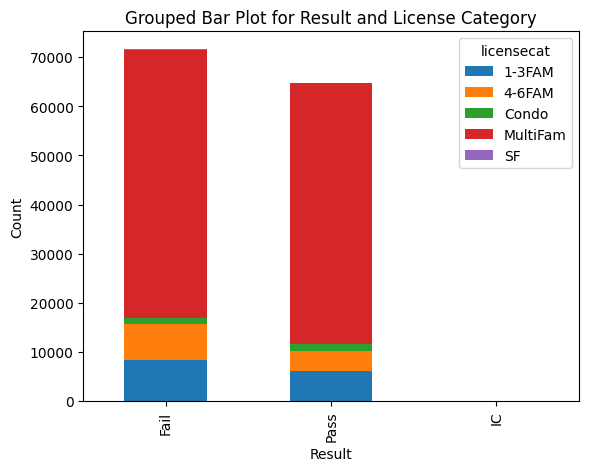

In [19]:
# Group the data by 'result' and 'licensecat', and count the occurrences
grouped_data = sub.groupby(['result', 'licensecat']).size().unstack()

# Plot the grouped bar plot
ax = grouped_data.plot(kind='bar', stacked=True)

# Add labels and title to the plot
plt.xlabel('Result')
plt.ylabel('Count')
plt.title('Grouped Bar Plot for Result and License Category')

# Rename the x-axis tick labels
ax.set_xticklabels(['Fail', 'Pass', 'IC'])

# Show the plot
plt.show()


### Statistically Measuring the Strength of Relationship between Variables
* Categorical Vs Categorical: Use **Chi-Square Test**
* Categorical Vs Continuous: Use **ANOVA Test**
* Continuous Vs Continuous: Use **Correlation Test(Matrix)**

In our case, we can look at the depth of relationship between licensecat versus result (whether the inspection failed,passed,IC). 
* For continuous, we could consider time/date either based on hours/days/months/seasonal.

**Chi-Square Test**
* H0: No association between the license and result category
* H1: There is an association between the license and result category


In [20]:
from scipy.stats import chi2_contingency

# Assuming you have a DataFrame named 'gdf' with columns 'licensecat' and 'result'.

# Create a contingency table of 'licensecat' and 'result'.
contingency_table = pd.crosstab(sub['licensecat'], sub['result'])

# Perform the chi-squared test.
chi2, p, dof, expected = chi2_contingency(contingency_table)

# Print the results.
print("Chi-Squared Statistic:", chi2)
print("P-value:", p)
print("Degrees of Freedom:", dof)
print("Expected Frequencies Table:")
print(pd.DataFrame(expected, index=contingency_table.index, columns=contingency_table.columns))


Chi-Squared Statistic: 1052.1365571412307
P-value: 8.296665777554501e-222
Degrees of Freedom: 8
Expected Frequencies Table:
result                 0             1          2
licensecat                                       
1-3FAM       7579.883865   6853.883514   4.232621
4-6FAM       5979.697827   5406.963099   3.339074
Condo        1491.511987   1348.655150   0.832863
MultiFam    56489.507127  51078.949027  31.543846
SF             92.399194     83.549210   0.051596


#### Intepretation
1. **Chi-Squared Statistic**: It is a measure of the strength of the association between the two categorical variables. In this case, the chi-squared statistic value is approximately 902.85.
2. **P-value** is used to determine the significance of the association. In this case, the p-value is approximately 8.29e-222, which is extremely small (close to zero). 
* A very small p-value **indicates strong evidence against the null hypothesis, suggesting that there is a significant association between the two categorical variables.**
3. Expected Frequencies Table: shows the expected counts if there were no association between the two variables. It provides the theoretical counts based on the assumption of independence between the 'licensecat' and 'result' categories.

To Conclude:
* The very low p-value (close to zero) indicates that there is a highly significant association between the 'licensecat', thats the type of building and 'result' (that's whether the unit passes or fails or IC the housing code). This means that the distribution of 'result' categories is not random but is related to the 'licensecat' categories. In other words, the type of building or apartment appears to have an impact on the inspection result.

NB: This tests only assesses association but does not imply causation. 


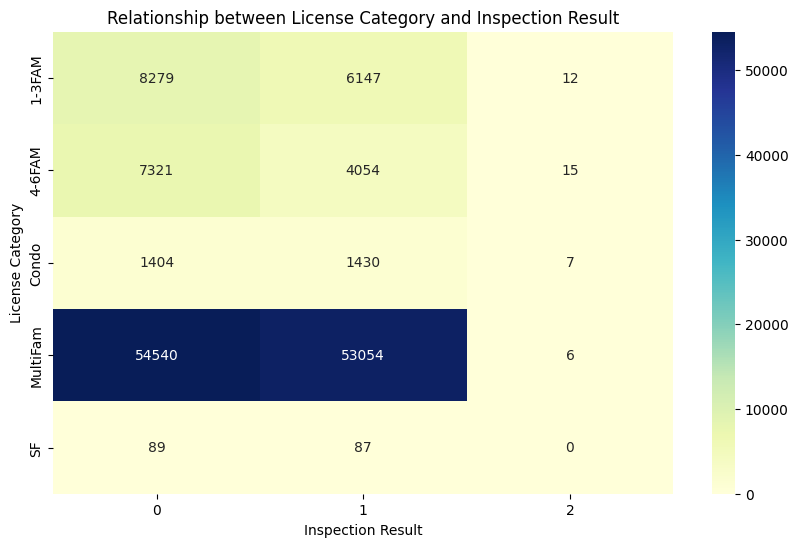

In [21]:
# Create a contingency table of 'licensecat' and 'result'.
contingency_table = pd.crosstab(sub['licensecat'], sub['result'])

# Plot a heatmap to visualize the relationship.
plt.figure(figsize=(10, 6))
sns.heatmap(contingency_table, annot=True, cmap='YlGnBu', fmt='d')

# Add labels and a title.
plt.xlabel('Inspection Result')
plt.ylabel('License Category')
plt.title('Relationship between License Category and Inspection Result')

# Show the plot.
plt.show()


#### Time Duration Analysis
* For case duration: Using 'adddttm' for the date the inspection was determined and 'resultdttm' for when the inspection was resulted.


In [22]:
from dateutil import parser

# Convert 'adddtttm' and 'resultdttm' columns to datetime format without seconds and milliseconds.
sub['adddttm'] = sub['adddttm'].apply(lambda x: parser.parse(x).strftime('%Y-%m-%d %H:%M'))
sub['resultdttm'] = sub['resultdttm'].apply(lambda x: parser.parse(x).strftime('%Y-%m-%d %H:%M'))

# Calculate the time difference between 'resdttm' and 'adddtttm'.
sub['time_difference'] = pd.to_datetime(sub['resultdttm'], format='%Y-%m-%d %H:%M') - pd.to_datetime(sub['adddttm'], format='%Y-%m-%d %H:%M')

# Convert the time difference to hours and minutes.
sub['time_difference_days'] = sub['time_difference'] / pd.Timedelta(days=1)
sub['time_difference_hours'] = sub['time_difference'] / pd.Timedelta(hours=1)


In [23]:
sub.head()


,apkey,licensecat,licenseno,addrkey,result,adddttm,scheddttm,compdttm,resultdttm,resultby,comments,gpsx,gpsy,gps_geom_2249,time_difference,time_difference_days,time_difference_hours
0,2420906,MultiFam,RINS-465810,695932,0,2022-08-22 15:13,2023-02-08 15:28:00+00,2023-02-08 16:46:00+00,2023-02-08 16:46,110900,Estefania Egred 617-542-3019,789192.698457,2.968625e+06,0101000020C9080000AD369C65911528410DD628AA18A6...,170 days 01:33:00,170.064583,4081.550000
1,2436040,1-3FAM,RINS-468097,158813,1,2022-02-16 17:18,2022-03-16 16:26:00+00,2022-03-16 15:51:00+00,2022-03-16 15:51,163574,Mal Nelson 617-418-8245,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,27 days 22:33:00,27.939583,670.550000
2,2436039,1-3FAM,RINS-468096,158813,1,2022-02-16 17:18,2022-03-16 16:26:00+00,2022-03-16 15:50:00+00,2022-03-16 15:50,163574,Mal Nelson 617-418-8245,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,27 days 22:32:00,27.938889,670.533333
3,2420907,MultiFam,RINS-465811,695933,0,2022-07-14 18:49,2022-08-22 16:53:00+00,2022-08-22 15:13:00+00,2022-08-22 15:13,149505,Luis 617-529-3510,789192.698457,2.968625e+06,0101000020C9080000AD369C65911528410DD628AA18A6...,38 days 20:24:00,38.850000,932.400000
4,2420907,MultiFam,RINS-465811,695933,0,2022-07-14 18:49,2022-08-22 16:53:00+00,2022-08-22 15:13:00+00,2022-08-22 15:13,149505,Luis 617-529-3510,789192.698457,2.968625e+06,0101000020C9080000AD369C65911528410DD628AA18A6...,38 days 20:24:00,38.850000,932.400000


In [24]:
# Calculate the average hours from the 'time_difference_hours' column.
average_hours = sub['time_difference_hours'].mean()

print(f"Average Hours: {average_hours}")


Average Hours: 9984.228382009846


In [25]:
import random

# Randomly pick an observation from 'time_difference_hours'.
random_observation = random.choice(sub['time_difference_hours'])

# Divide the randomly picked observation by 24 to get the number of days.
number_of_days = random_observation / 24

print(f"Randomly Picked Observation: {random_observation} hours")
print(f"Number of Days: {number_of_days} days")


Randomly Picked Observation: 814.5333333333333 hours
Number of Days: 33.93888888888889 days


* Running the above code multiple times gives us an idea of the number of days for an inspection to take place after being scheduled.
* I didn't rely on finding the average as we can see the above average gave us 10001 or 416 days which didn't make any sense.

**ANOVA Test**

* For the difference between (Opening and Completion time) versus License category
I am not sure the same can be said or done for result..


In [26]:
from scipy.stats import f_oneway

# Perform the ANOVA test.
result = f_oneway(*[sub[sub['licensecat'] == category]['time_difference_hours'] for category in sub['licensecat'].unique()])

print("ANOVA Test Results:")
print(f"F-statistic: {result.statistic}")
print(f"P-value: {result.pvalue}")


ANOVA Test Results:
F-statistic: 2159.2754590532245
P-value: 0.0


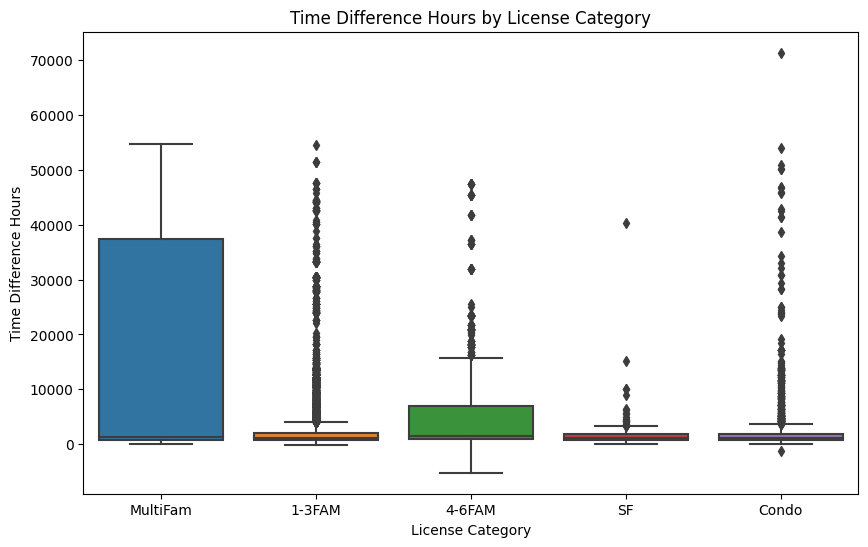

In [27]:
# Visualize the ANOVA results using boxplots.
plt.figure(figsize=(10, 6))
sns.boxplot(x='licensecat', y='time_difference_hours', data=sub)
plt.title('Time Difference Hours by License Category')
plt.xlabel('License Category')
plt.ylabel('Time Difference Hours')
plt.show()


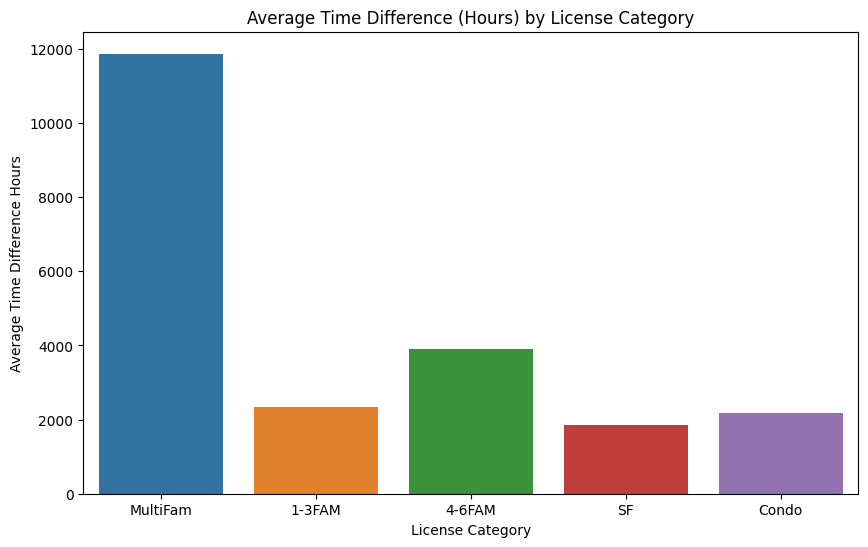

In [28]:
# Visualize the average time difference hours using a bar plot.
plt.figure(figsize=(10, 6))
sns.barplot(x='licensecat', y='time_difference_hours', data=sub, ci=None)  # Set ci=None to remove error bars.
plt.title('Average Time Difference (Hours) by License Category')
plt.xlabel('License Category')
plt.ylabel('Average Time Difference Hours')
plt.show()


### Encoding categorical features
#### Reasons for Encoding features or variables
1. Algorithms typically require numeric data. 
2. When a categorical feature is represented with numbers, for example, 1 for female and 2 for male, we need to encode the values so that they are recognized as categorical. 
3. The feature might actually be ordinal, with a discrete number of values that represent some meaningful ranking. Our models need to capture that ranking.
4. A categorical feature might have a large number of values (known as high cardinality), and we might want our encoding to collapse categories.

#### One-hot encoding

One-hot encoding a feature creates a binary vector for each value of that feature. 

So, if a feature, called result, has three unique values, 0, 1, and 2, one-hot encoding creates three binary vectors to represent those values. Recall from above that result 0 is a failed inspection, 1 is passed and 2 is incomplete.

* The first binary vector, which we can call **result_0**, has 1 whenever result has a value of 0, and 0 when it is 1 or 2.
* result_1 and result_2 would be coded similarly. 
* The transformed features, result_0, result_1, and result_2, are often referred to as dummy variables. 


In [29]:
# we import the necessary packages for it
import feature_engine.selection as fesel
from sklearn.model_selection import train_test_split
from feature_engine.encoding import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split


In [30]:
# We reconvert original mapping dictionary of the result column before applying One-Hot Encoding
original_mapping = {0: 'Fail', 1: 'Pass', 2: 'IC'}

# Reverse the mapping and convert back to original strings
sub['result'] = sub['result'].replace(original_mapping)

# Display the updated 'result' column
print(sub['result'])


0         Fail
1         Pass
2         Pass
3         Fail
4         Fail
          ... 
136440    Fail
136441    Fail
136442    Pass
136443    Pass
136444    Pass
Name: result, Length: 136445, dtype: object


In [31]:
feature_cols = ['licensecat','result']

# Create one-hot encoded columns for the specified feature columns.
one_hot_encoded = pd.get_dummies(sub[feature_cols])

# Convert boolean values to integers (0 and 1).
one_hot_encoded = one_hot_encoded.astype(int)

# Concatenate the one-hot encoded columns back to the original 'sub' dataframe.
sub = pd.concat([sub, one_hot_encoded], axis=1)

# Drop the original categorical columns from 'sub' if needed, i will keep it for now
# sub.drop(feature_cols, axis=1, inplace=True)

sub.head()


,apkey,licensecat,licenseno,addrkey,result,adddttm,scheddttm,compdttm,resultdttm,resultby,...,time_difference_days,time_difference_hours,licensecat_1-3FAM,licensecat_4-6FAM,licensecat_Condo,licensecat_MultiFam,licensecat_SF,result_Fail,result_IC,result_Pass
0,2420906,MultiFam,RINS-465810,695932,Fail,2022-08-22 15:13,2023-02-08 15:28:00+00,2023-02-08 16:46:00+00,2023-02-08 16:46,110900,...,170.064583,4081.550000,0,0,0,1,0,1,0,0
1,2436040,1-3FAM,RINS-468097,158813,Pass,2022-02-16 17:18,2022-03-16 16:26:00+00,2022-03-16 15:51:00+00,2022-03-16 15:51,163574,...,27.939583,670.550000,1,0,0,0,0,0,0,1
2,2436039,1-3FAM,RINS-468096,158813,Pass,2022-02-16 17:18,2022-03-16 16:26:00+00,2022-03-16 15:50:00+00,2022-03-16 15:50,163574,...,27.938889,670.533333,1,0,0,0,0,0,0,1
3,2420907,MultiFam,RINS-465811,695933,Fail,2022-07-14 18:49,2022-08-22 16:53:00+00,2022-08-22 15:13:00+00,2022-08-22 15:13,149505,...,38.850000,932.400000,0,0,0,1,0,1,0,0
4,2420907,MultiFam,RINS-465811,695933,Fail,2022-07-14 18:49,2022-08-22 16:53:00+00,2022-08-22 15:13:00+00,2022-08-22 15:13,149505,...,38.850000,932.400000,0,0,0,1,0,1,0,0


In [32]:
# Drop the original categorical columns from 'sub' if needed, i will keep it for now
sub.drop(feature_cols, axis=1, inplace=True)

sub.tail(15)                                         # look at the last 15 observations


,apkey,licenseno,addrkey,adddttm,scheddttm,compdttm,resultdttm,resultby,comments,gpsx,...,time_difference_days,time_difference_hours,licensecat_1-3FAM,licensecat_4-6FAM,licensecat_Condo,licensecat_MultiFam,licensecat_SF,result_Fail,result_IC,result_Pass
136430,2420914,RINS-465818,696004,2022-07-14 16:53,2022-09-07 17:07:00+00,2022-09-07 15:07:00+00,2022-09-07 15:07,149505,Luis 617-529-3510-Arrival-10:00<div>No need to...,788742.635699,...,54.926389,1318.233333,0,0,0,1,0,1,0,0
136431,2420914,RINS-465818,696004,2022-07-14 16:53,2022-09-07 17:07:00+00,2022-09-07 15:07:00+00,2022-09-07 15:07,149505,Luis 617-529-3510-Arrival-10:00<div>No need to...,788742.635699,...,54.926389,1318.233333,0,0,0,1,0,1,0,0
136432,1912330,RINS-397098,696050,2019-06-05 18:35,2022-07-28 15:26:00+00,2022-07-28 19:40:00+00,2022-07-28 19:40,158090,"<span style=""color: rgb(0, 0, 0); font-family:...",749050.247236,...,1149.045139,27577.083333,0,0,0,1,0,0,1,0
136433,2404860,RINS-464018,696084,2021-12-10 15:37,2022-08-17 18:26:00+00,2022-08-17 14:32:00+00,2022-08-17 14:32,075622,Lidia 617-319-0744 COF vacant &amp; paid,765080.090033,...,249.954861,5998.916667,0,0,0,1,0,0,0,1
136434,2563605,RINS-490530,696157,2022-08-24 16:35,2022-10-05 16:34:00+00,2022-10-05 15:42:00+00,2022-10-05 15:42,149505,Shane Baron 617-266-8860,768055.726613,...,41.963194,1007.116667,0,0,0,1,0,0,0,1
136435,2563604,RINS-490529,696158,2022-08-24 16:35,2022-10-05 16:33:00+00,2022-10-05 15:40:00+00,2022-10-05 15:40,149505,Shane Baron 617-266-8860,768035.834593,...,41.961806,1007.083333,0,0,0,1,0,0,0,1
136436,2568019,RINS-491119,696166,2022-10-26 14:54,2022-12-21 17:55:00+00,2022-12-21 14:30:00+00,2022-12-21 14:30,163574,Maureen Conley 617-541-6239,782731.231547,...,55.983333,1343.600000,0,0,1,0,0,0,0,1
136437,2568019,RINS-491119,696166,2022-08-30 16:05,2022-09-29 18:30:00+00,2022-09-29 19:06:00+00,2022-09-29 19:06,075622,Maureen Conley 617-541-6239,782731.231547,...,30.125694,723.016667,0,0,1,0,0,1,0,0
136438,2671811,RINS-520190,697479,2023-01-30 15:50,2023-04-03 19:02:00+00,2023-04-03 15:55:00+00,2023-04-03 15:55,110900,Zoe Agorianitis 617-536-6466<div>Natty please ...,770981.906785,...,63.003472,1512.083333,0,0,0,1,0,1,0,0
136439,2671811,RINS-520190,697479,2023-04-03 16:02,2023-06-06 16:50:00+00,2023-06-06 15:01:00+00,2023-06-06 15:01,149875,Zoe Agorianitis 617-536-6466-Arrival 10:00-Lef...,770981.906785,...,63.957639,1534.983333,0,0,0,1,0,0,0,1


**From the one-hot encoding, we have about 5 new numeric columns for license category, 3 new numeric columns for result & 3 new for time (in days, hours & minutes).** 

In [ ]:
# Export the 'sub' DataFrame to a CSV file
sub.to_csv('sub_data.csv', index=False)


In [ ]:
# import libraries for geospatial analysis
import geopandas as gpd
import splot

from pysal.viz import splot
from splot.esda import plot_moran
import contextily
from IPython.display import display, Markdown, display_latex, display_markdown, display_html

# More packages for developing spatial hypothesis test.
from pysal.explore import esda
from pysal.lib import weights
from numpy.random import seed


### Exploratory Spatial Data Analysis ESDA
* Looked at on **ArcGIS Pro** 


In [ ]:
# Drop all rows with NaN values in the 'gpsx' column
# gdf = gdf.dropna(subset=['gpsx'])
# Reset the index to begin from 0
# gdf = gdf.reset_index(drop=True)

# gdf_sub.tail()

### Hypothesis Testing and Spatial Randomness
#### Hypothesis Testing and Spatial Randomness

* A **spatial structure** is the presence of a pattern within data across geographic space. Data that has no spatial structure is said to have been generated by an **independent random process (IRP).** 
* This **IRP** result is data that exhibits **complete spatial randomness (CSR).** 
* IRP and CSR used interchangeably. IRP/CSR must satisfy two conditions in order to construct a valid hypothesis test:

1. Any observation must have an equal probability of occurring in any location, Thus, it vary from place to place based on changes in the underlying area. This is known as a **first-order effect**. As an example, the distribution of an infectious disease will vary across a study area, based on underlying environmental factors.
2. The location of an observation is independent and does not impact the location of any other observation, thus, it varies from place to place due to interaction effects between observations.. This is known as a **second-order effect.** To continue the previous example on infectious diseases, the intensity of the disease is expected to vary and is dependent on locations where there are infected people, whereas other infections will cluster around the infected people.

In our domain for analyzing asthma triggers in Greater Boston, the **first-order effect** will be the distrition of the housing code violations for rodents and mold (which are known to be asthma triggers) in the City.
While the **second-order effect** is the variation of the degree of violations and how dependent it is on locations where there are most violations.

#### Hypothesis 
* H0: The data is distributed randomly across space.
* Ha: The data exhibits a spatial structure and is not randomly distributed.

#### Using Moran’s I
**Moran’s I** measures spatial autocorrelation of data based on feature values and feature locations. 
Spatial autocorrelation measures the variation of a variable by taking an observation and seeing how similar or different it is compared to other observations within its neighborhood. 


### Global Spatial Autocorrelation


In [ ]:
# Convert the pandas DataFrame to a geopandas GeoDataFrame
gdf = gpd.GeoDataFrame(sub, geometry=gpd.points_from_xy(sub.gpsx,sub.gpsy, crs=4326))

gdf.head()


In [16]:
# Convert POINT geometries to Polygon format with buffer distance of 0 (essentially converting points to polygons)
gdf['geometry'] = gdf['geometry'].buffer(0)


In [17]:
# Calculate the Queen's weights
w = weights.Queen.from_dataframe(gdf)


In [ ]:
# Row-standardization
# w.transform = 'R'

In [18]:
# Calculate the spatial lag
gdf['result_lag'] = weights.spatial_lag.lag_spatial(w, gdf['result'])

# Standardize the variable of interest and the lag variable
gdf['result_std'] = (gdf['result'] - gdf['result'].mean())
gdf['result_lag_std'] = (gdf['result_lag'] - gdf['result_lag'].mean())


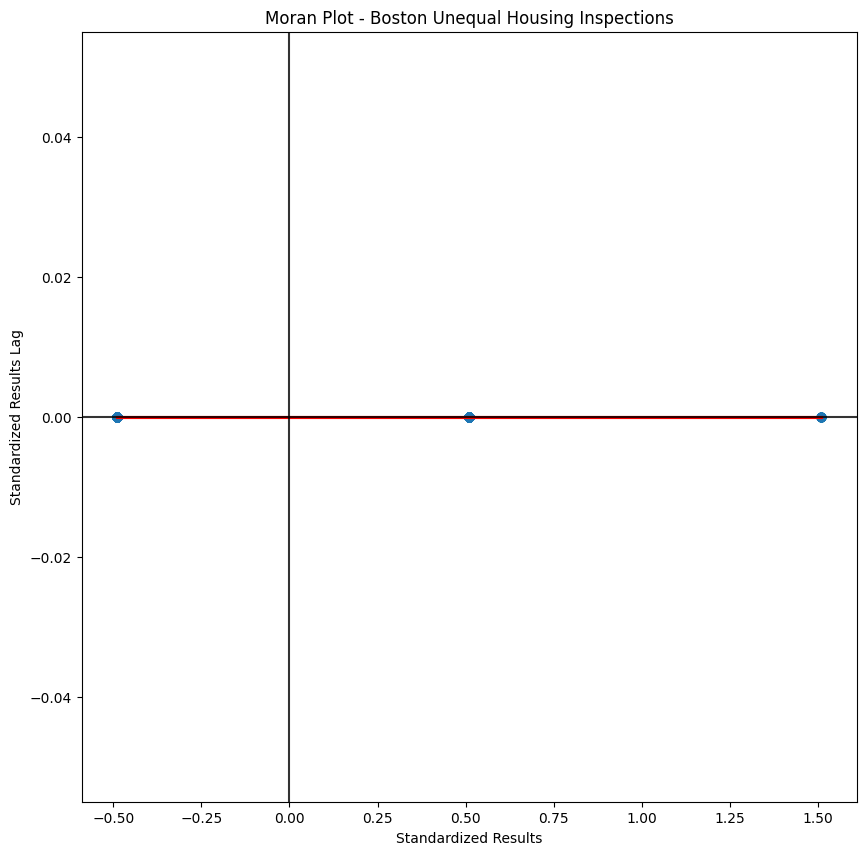

In [19]:
f, ax = plt.subplots(1, figsize=(10, 10))
sns.regplot(
    x='result_std', # variable of interest
    y='result_lag_std', # spatial lag
    ci=None, # suppress the plotting of the confidence interval
    data=gdf, # dataset
    line_kws={'color':'r'}
)

ax.axvline(0, c='k', alpha=0.8)
ax.axhline(0, c='k', alpha=0.8)

ax.set_title('Moran Plot - Boston Unequal Housing Inspections')
ax.set_xlabel('Standardized Results')
ax.set_ylabel('Standardized Results Lag')
plt.show()


In [20]:
morans_stat = esda.moran.Moran(gdf['result'], w)
display(Markdown(f"""**Morans I:** {morans_stat.I}"""))
display(Markdown(f"""**p-value:** {morans_stat.p_sim}"""))


IOPub data rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_data_rate_limit`.

Current values:
NotebookApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
NotebookApp.rate_limit_window=3.0 (secs)



('WARNING: ', 131743, ' is an island (no neighbors)')
('WARNING: ', 131744, ' is an island (no neighbors)')
('WARNING: ', 131745, ' is an island (no neighbors)')
('WARNING: ', 131746, ' is an island (no neighbors)')
('WARNING: ', 131747, ' is an island (no neighbors)')
('WARNING: ', 131748, ' is an island (no neighbors)')
('WARNING: ', 131749, ' is an island (no neighbors)')
('WARNING: ', 131750, ' is an island (no neighbors)')
('WARNING: ', 131751, ' is an island (no neighbors)')
('WARNING: ', 131752, ' is an island (no neighbors)')
('WARNING: ', 131753, ' is an island (no neighbors)')
('WARNING: ', 131754, ' is an island (no neighbors)')
('WARNING: ', 131755, ' is an island (no neighbors)')
('WARNING: ', 131756, ' is an island (no neighbors)')
('WARNING: ', 131757, ' is an island (no neighbors)')
('WARNING: ', 131758, ' is an island (no neighbors)')
('WARNING: ', 131759, ' is an island (no neighbors)')
('WARNING: ', 131760, ' is an island (no neighbors)')
('WARNING: ', 131761, ' is a

**Morans I:** nan

**p-value:** 0.001

(<Figure size 1000x400 with 2 Axes>,
 array([<Axes: title={'center': 'Reference Distribution'}, xlabel='Moran I: nan', ylabel='Density'>,
        <Axes: title={'center': 'Moran Scatterplot (nan)'}, xlabel='Attribute', ylabel='Spatial Lag'>],
       dtype=object))

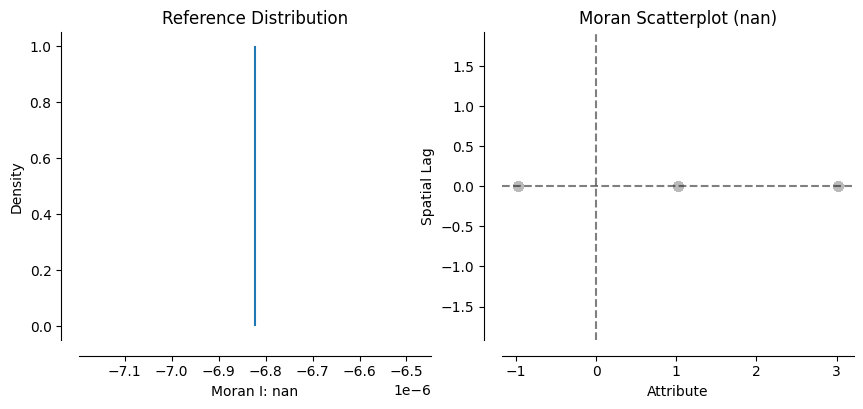

In [21]:
plot_moran(morans_stat)


This does not seem like a good metric for this categorical variables that we have. Works better with continues variables.


In [22]:
# Drop rows with empty or invalid geometries
gdf = gdf.dropna(subset=['geometry'])


In [23]:
# Check the number of observations in the 'geometry' and 'result' columns
num_geometry_observations = len(gdf['geometry'])
num_result_observations = len(gdf['result'])

# Compare the number of observations
if num_geometry_observations == num_result_observations:
    print("The 'geometry' and 'result' columns have the same number of observations.")
else:
    print("The 'geometry' and 'result' columns have different numbers of observations.")


The 'geometry' and 'result' columns have the same number of observations.


In [24]:
# Perform the Local Spatial Autocorrelation (Moran's I) on the categorical column
moran_loc = Moran_Local(gdf['result'], w)

# Access the Moran's I Local statistic, z-scores, and p-values
moran_loc_I = moran_loc.Is
moran_loc_z_sim = moran_loc.z_sim
p_values = moran_loc.p_sim

# Print the results
print("Moran's I Local:", moran_loc_I)
print("Z-scores:", moran_loc_z_sim)
print("p-values:", p_values)


NameError: name 'Moran_Local' is not defined

In [25]:
# More packages for developing spatial hypothesis test.
from pysal.explore import esda
from pysal.lib import weights
from numpy.random import seed


In [26]:
import numpy as np
from esda.moran import Moran

# Convert the 'licensecat' column to category dtype
gdf['licensecat'] = gdf['licensecat'].astype('category')

# Set seed for reproducibility
np.random.seed(54321)

# Set the variables of interest
variables_of_interest = ['licensecat','result']

for voi in variables_of_interest:
    morans_stat = esda.moran.Moran(gdf[voi], w)
    display(Markdown(f"""**Morans I for {voi}:** {morans_stat.I}"""))
    display(Markdown(f"""**p-value for {voi}:** {morans_stat.p_sim}"""))
    plot_moran(morans_stat)
    

TypeError: ufunc 'divide' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

### Point PatterN Analysis
This centers around the patterns present within point data instead of the attributes associated with the point data.
* This is quintessential in studies of infectious diseases, helps check whether diseases are clustered together around infected individuals or areas.

#### Ripley’s alphabet functions


In [44]:
# Spatial Statistics
from pointpats import distance_statistics, QStatistic, random, PointPattern, PoissonPointProcess, PoissonClusterPointProcess, Window, poly_from_bbox
import libpysal as ps
from libpysal.cg import shapely_ext

# Setting matplotlib jupyter options to show plots in notebook
%matplotlib inline

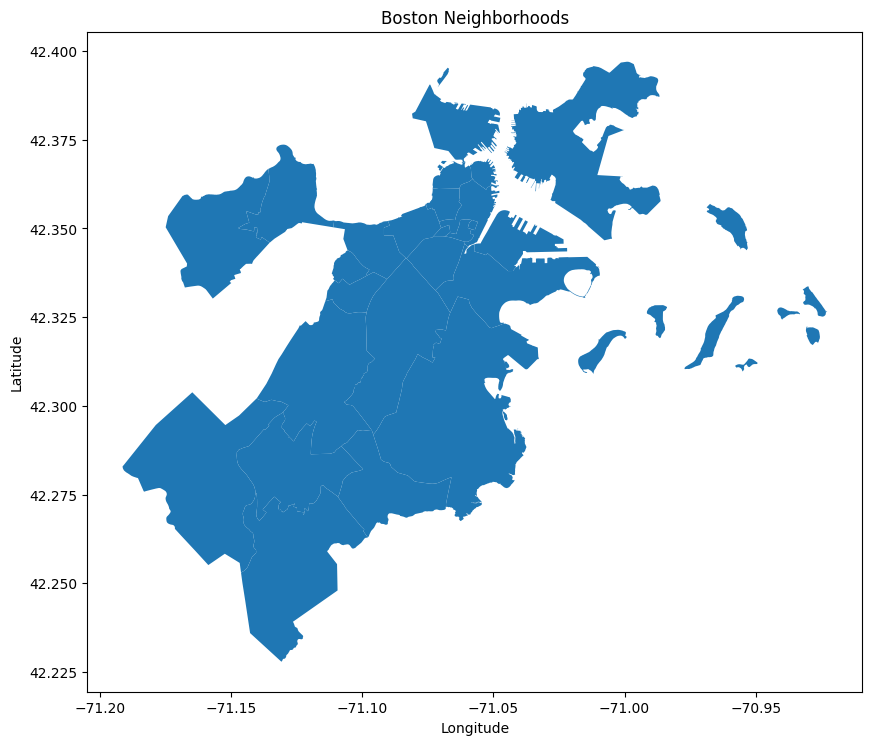

In [51]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Replace the file path with your actual file path
shapefile_path = r"C:\Users\174006\Desktop\Boston\Boston_Neighborhoods.shp"

def plot_shapefile(shapefile_path):
    # Read the shapefile using geopandas
    gdf = gpd.read_file(shapefile_path)

    # Plot the map
    fig, ax = plt.subplots(figsize=(10, 10))
    gdf.plot(ax=ax)
    plt.title("Boston Neighborhoods")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.show()

# Call the function to plot the map
plot_shapefile(shapefile_path)


In [53]:
# Replace the file path with your actual file path
shapefile_path = r"C:\Users\174006\Desktop\Boston\Boston_Neighborhoods.shp"
boston = gpd.read_file(shapefile_path)
boston_city = boston.dissolve()
boston_city


,geometry,OBJECTID,Name,Acres,Neighborho,SqMiles,ShapeSTAre,ShapeSTLen
0,"MULTIPOLYGON (((-71.06838 42.27084, -71.06841 ...",27,Roslindale,1605.568237,15,2.51,6.993827e+07,53563.912597


In [60]:
# Access shapefile of the city of boston
bn = ps.io.open(shapefile_path)
polys = [shp for shp in bn]


In [61]:
city = shapely_ext.cascaded_union(polys)

# create window from boston city boundary
window = Window(city.parts)


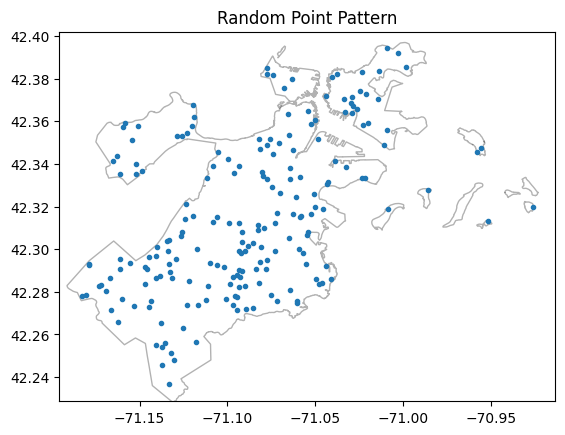

In [62]:
# Here, we're simulating a csr process in the window being Boston (200 points, 1 realization)
# setting "asPP" True generates a point pattern
# setting "conditioning" to false simulates a N-conditioned CSR
np.random.seed(5)
samples = PoissonPointProcess(window, 200, 1, conditioning=False, asPP=True)

pp_csr = samples.realizations[0] # simulated point pattern

pp_csr.plot(window=True, hull=False, title='Random Point Pattern')


The above figure may appear to be somewhat clustered and not look like randomly derived data. 
This is because the human brain is built to try and detect patterns, and it wants to see a pattern in this data. 
However, this data is generated by taking random points from a Poisson distribution.


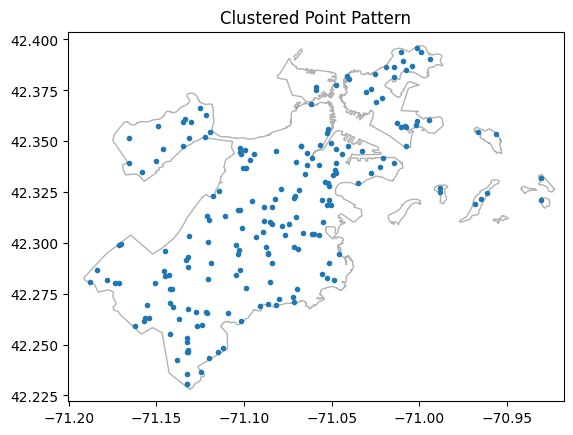

In [64]:
np.random.seed(10)
csamples = PoissonClusterPointProcess(window, 200, 5, 0.5, 1, asPP=True)
pp_pcp = csamples.realizations[0]
pp_pcp.plot(window=True, hull=False, title='Clustered Point Pattern')


In [124]:
# Convert the pandas DataFrame to a geopandas GeoDataFrame
gdf_new = gpd.GeoDataFrame(
    sub, geometry=gpd.points_from_xy(sub.gpsx,sub.gpsy),
    crs="EPSG:4326"
)


In [125]:
# Step 1: Define a function to check if the geometry is empty or contains 'POINT EMPTY'.
def is_invalid_geometry(geom):
    return geom.is_empty or geom.geom_type == 'POINT EMPTY'

# Step 2: Use the defined function to create a boolean mask for invalid geometries and NaN values.
mask_invalid_geometries = gdf_new['geometry'].apply(is_invalid_geometry)
mask_nan_values = gdf_new['geometry'].isna()

# Step 3: Combine the boolean masks using logical OR (|).
mask_invalid_rows = mask_invalid_geometries | mask_nan_values

# Step 4: Use the mask to filter out the rows with invalid geometries and NaN values.
gdf_new = gdf_new[~mask_invalid_rows]
gdf_new.head(20)


,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry
24,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
25,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
26,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
27,2436039,1-3FAM,RINS-468096,158813,Pass,2022-03-16 15:50:00+00,163574,2022-03-16 15:50:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
28,2436040,1-3FAM,RINS-468097,158813,Pass,2022-03-16 15:51:00+00,163574,2022-03-16 15:51:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
29,2631787,1-3FAM,RINS-512533,158846,Pass,2022-12-08 16:12:00+00,122496,2022-12-08 16:12:00+00,Rental Unit Inspection,783724.783078,2.963659e+06,0101000020C90800007C8CEF90D9EA27419F04364F659C...,POINT (783724.78308 2963658.61884)
30,2631787,1-3FAM,RINS-512533,158846,Pass,2022-12-08 16:12:00+00,122496,2022-12-08 16:12:00+00,Rental Unit Inspection,783724.783078,2.963659e+06,0101000020C90800007C8CEF90D9EA27419F04364F659C...,POINT (783724.78308 2963658.61884)
31,2631788,1-3FAM,RINS-512534,158846,Pass,2022-12-08 16:12:00+00,122496,2022-12-08 16:12:00+00,Rental Unit Inspection,783724.783078,2.963659e+06,0101000020C90800007C8CEF90D9EA27419F04364F659C...,POINT (783724.78308 2963658.61884)
32,2323666,1-3FAM,RINS-456732,158901,Fail,2021-08-19 17:03:00+00,75622,2021-08-19 17:03:00+00,Rental Unit Inspection,783461.412325,2.963695e+06,0101000020C90800007D4F1CD3CAE82741D7202388779C...,POINT (783461.41233 2963695.06357)
33,2323666,1-3FAM,RINS-456732,158901,Fail,2021-08-19 17:03:00+00,75622,2021-08-19 17:03:00+00,Rental Unit Inspection,783461.412325,2.963695e+06,0101000020C90800007D4F1CD3CAE82741D7202388779C...,POINT (783461.41233 2963695.06357)


In [126]:
gdf_new.tail()


,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry
146505,2671814,MultiFam,RINS-520193,697480,Fail,2023-04-03 15:44:00+00,110900,2023-04-03 15:44:00+00,Rental Unit Inspection,770981.906785,2.951567e+06,0101000020C9080000411546D04B87274180790E5FC784...,POINT (770981.90678 2951566.74263)
146506,2656482,MultiFam,RINS-518086,697548,Pass,2023-03-02 14:35:00+00,149875,2023-03-02 14:35:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)
146507,2656483,MultiFam,RINS-518087,697548,Pass,2023-03-17 14:23:00+00,110900,2023-03-17 14:23:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)
146508,2656484,MultiFam,RINS-518088,697548,Pass,2023-03-23 15:11:00+00,149505,2023-03-23 15:11:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)
146509,2656485,MultiFam,RINS-518089,697548,Pass,2023-03-27 14:10:00+00,149875,2023-03-27 14:10:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)


In [128]:
import pyproj

# Define the EPSG code for the UTM coordinate system used in the 'gpsx' and 'gpsy' columns.
epsg_code_utm = '32618'

# Define the EPSG code for the WGS 84 (latitude-longitude) coordinate system.
epsg_code_wgs84 = '4326'

# Create a Proj transformer to convert from UTM to WGS 84.
transformer = pyproj.Transformer.from_crs(epsg_code_utm, epsg_code_wgs84, always_xy=True)

# Convert 'gpsx' and 'gpsy' to latitude (X) and longitude (Y) columns.
gdf_new['X'], gdf_new['Y'] = transformer.transform(gdf_new['gpsx'].values, gdf_new['gpsy'].values)
gdf_new.head()


,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry,X,Y
24,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665
25,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665
26,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665
27,2436039,1-3FAM,RINS-468096,158813,Pass,2022-03-16 15:50:00+00,163574,2022-03-16 15:50:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665
28,2436040,1-3FAM,RINS-468097,158813,Pass,2022-03-16 15:51:00+00,163574,2022-03-16 15:51:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665


<Axes: >

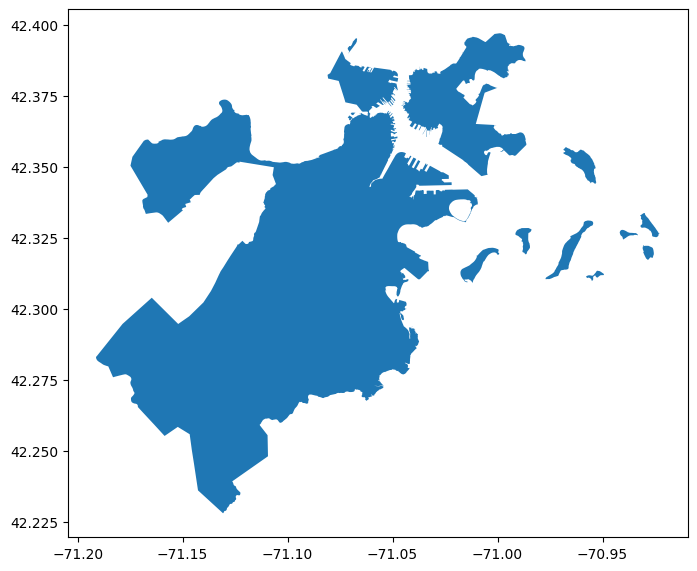

In [143]:
f, ax = plt.subplots(1, figsize=(8, 8))
boston_city.plot(ax = ax,color=None, zorder=1)


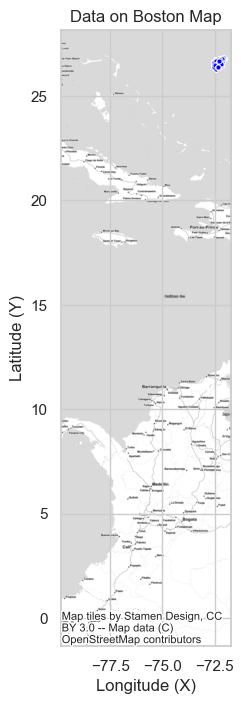

In [151]:
import contextily as ctx

# Create a joint plot using seaborn with 'X' (longitude) and 'Y' (latitude) columns from 'gdf_new'.
sns.set(style='whitegrid')
plt.figure(figsize=(10, 8))

# Use 'point' for marker instead of 'o'.
sns.scatterplot(data=gdf_new, x='X', y='Y', marker='.', color='blue', s=50, alpha=0.7)

# Add the basemap of Boston using contextily.
ctx.add_basemap(ax=plt.gca(), crs=gdf_new.crs.to_string(), source=ctx.providers.Stamen.TonerLite)

# Set aspect ratio to equal to prevent stretching of latitude axis.
plt.gca().set_aspect('equal')

# Show the plot.
plt.title('Data on Boston Map')
plt.xlabel('Longitude (X)')
plt.ylabel('Latitude (Y)')
plt.show()


ValueError: cannot convert float NaN to integer

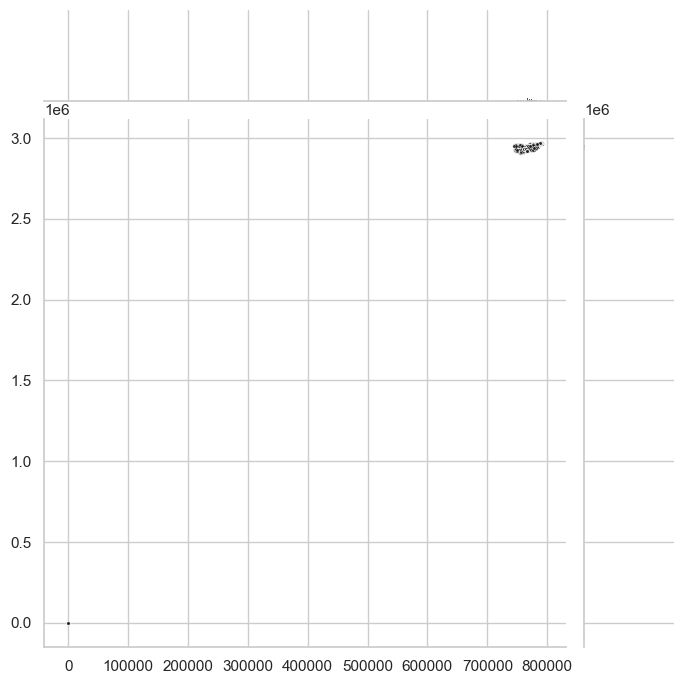

In [153]:
# Create a better visualization
joint_axes = sns.jointplot(
    x=gdf_new.geometry.x, 
    y=gdf_new.geometry.y, 
    data=gdf_new, 
    s=5, 
    height=7,
color='k');

contextily.add_basemap(
    joint_axes.ax_joint,
    crs="EPSG:4326",
    source=contextily.providers.Stamen.TonerLite
);


In [104]:
# Step 1: Extract 'gpsx' and 'gpsy' as 1D arrays from the GeoDataFrame.
gpsx_values = gdf['gpsx'].to_numpy()
gpsy_values = gdf['gpsy'].to_numpy()

# Step 2: Create a point pattern using the 'gpsx' and 'gpsy' coordinates.
point_pattern = pointpats.PointPattern(gpsx_values, gpsy_values)

# Step 3: Calculate Ripley's G function using the 'g_test()' function.
ripley_g = pointpats.g_test(point_pattern)

# The variable 'ripley_g' now contains the result of the G function test, including observed and expected values.

# You can access the observed and expected values from the 'ripley_g' variable as follows:
observed = ripley_g.observed
expected = ripley_g.expected

# You can also calculate the G function values for different distances using 'ripley_g.d'.
g_values = np.array(ripley_g.d)

# The 'g_values' variable now co

ValueError: Length mismatch: Expected axis has 1 elements, new values have 2 elements

In [ ]:
# Step 1: Drop 'POINT EMPTY' rows
gdf_new = gdf_new[~gdf_new.geometry.is_empty]

# Step 2: Convert 'geometry' column to Point geometries (assuming they are points representing centroids of polygons)
gdf_new['geometry'] = gdf_new.apply(lambda row: Point(row.geometry), axis=1)

# Step 3: Check and set the CRS of GeoDataFrames (if they are not already the same)
if gdf_new.crs != boston_city.crs:
    gdf_new = gdf_new.to_crs(boston_city.crs)

# Step 4: Plot the data from 'gdf_new' on the 'boston_city' map with contextily basemap
fig, ax = plt.subplots(figsize=(10, 10))
boston_city.plot(ax=ax, color='lightgrey', edgecolor='black')
gdf_new.plot(ax=ax, color='red', alpha=0.5, markersize=50)

# Add contextily basemap
contextily.add_basemap(ax, crs=boston_city.crs, source=contextily.providers.Stamen.Terrain)

# Apply seaborn styling
sns.set_style('whitegrid')

plt.title("Unequal Housing Data on Boston Map")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


In [106]:
gdf.tail(20)

,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry,result_lag,result_std,result_lag_std
146490,2656478,MultiFam,RINS-518082,697411,1,2022-12-29 16:24:00+00,170713,2022-12-29 16:24:00+00,Rental Unit Inspection,766575.515401,2.923028e+06,0101000020C9080000619AE207DF642741B0DBCEE4094D...,POLYGON EMPTY,0.0,0.509774,0.0
146491,2187006,1-3FAM,RINS-439390,697427,0,2021-05-03 19:01:00+00,134922,2021-05-03 19:01:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146492,2187006,1-3FAM,RINS-439390,697427,1,2021-09-30 15:23:00+00,149875,2021-09-30 15:23:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,0.509774,0.0
146493,2187006,1-3FAM,RINS-439390,697427,0,2020-12-16 16:33:00+00,149875,2020-12-16 16:33:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146494,2187006,1-3FAM,RINS-439390,697427,0,2021-07-09 14:11:00+00,122496,2021-07-09 14:11:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146495,2187006,1-3FAM,RINS-439390,697427,0,2021-06-07 18:14:00+00,134922,2021-06-07 18:14:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146496,2187006,1-3FAM,RINS-439390,697427,0,2021-08-25 14:55:00+00,148496,2021-08-25 14:55:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146497,2187006,1-3FAM,RINS-439390,697427,1,2023-01-18 19:14:00+00,149875,2023-01-18 19:14:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,0.509774,0.0
146498,2656479,MultiFam,RINS-518083,697447,1,2023-01-26 18:34:00+00,149875,2023-01-26 18:34:00+00,Rental Unit Inspection,766575.515401,2.923028e+06,0101000020C9080000619AE207DF642741B0DBCEE4094D...,POLYGON EMPTY,0.0,0.509774,0.0
146499,2656480,MultiFam,RINS-518084,697455,1,2023-01-30 16:10:00+00,149505,2023-01-30 16:10:00+00,Rental Unit Inspection,766575.515401,2.923028e+06,0101000020C9080000619AE207DF642741B0DBCEE4094D...,POLYGON EMPTY,0.0,0.509774,0.0


### References

